<a href="https://colab.research.google.com/github/aashish003/BIS-LAB_1BF24CS003/blob/main/Ant_Colony_Optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iteration  10 | Current best:  27.0 | Best so far:  27.0
Iteration  20 | Current best:  27.0 | Best so far:  27.0
Iteration  30 | Current best:  27.0 | Best so far:  27.0
Iteration  40 | Current best:  27.0 | Best so far:  27.0
Iteration  50 | Current best:  27.0 | Best so far:  27.0
Iteration  60 | Current best:  27.0 | Best so far:  27.0
Iteration  70 | Current best:  27.0 | Best so far:  27.0
Iteration  80 | Current best:  27.0 | Best so far:  27.0
Iteration  90 | Current best:  27.0 | Best so far:  27.0
Iteration 100 | Current best:  27.0 | Best so far:  27.0

========== FINAL RESULT ==========
Best objective value: 27

J1:
  Operation 1 -> M1, processing time = 4 hours
  Operation 2 -> M4, processing time = 4 hours
  Operation 3 -> M5, processing time = 5 hours

J2:
  Operation 1 -> M2, processing time = 4 hours
  Operation 2 -> M3, processing time = 5 hours
  Operation 3 -> M6, processing time = 4 hours

J3:
  Operation 1 -> M1, processing time = 5 hours
  Operation 2 -> M4, proc

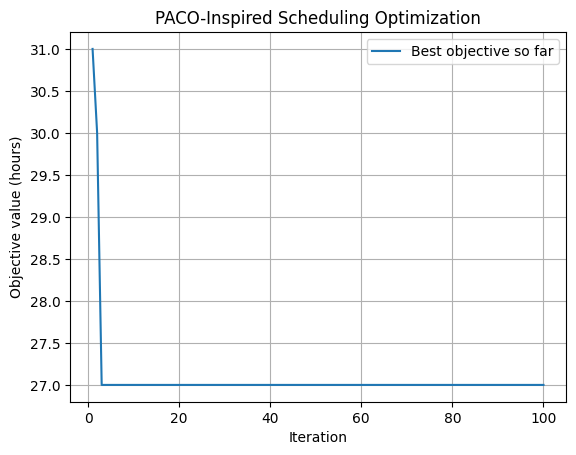

In [ ]:

import random
import math

# -----------------------------------------
# 1. SAMPLE TEXTILE FACTORY DATA
# -----------------------------------------
# Each job has 3 operations.
# Each operation has 2 possible machines.
# The values are processing times in hours.

jobs = {
    "J1": [
        {"M1": 4, "M2": 5},
        {"M3": 6, "M4": 4},
        {"M5": 5, "M6": 7}
    ],
    "J2": [
        {"M1": 6, "M2": 4},
        {"M3": 5, "M4": 7},
        {"M5": 6, "M6": 4}
    ],
    "J3": [
        {"M1": 5, "M2": 6},
        {"M3": 7, "M4": 5},
        {"M5": 4, "M6": 6}
    ],
    "J4": [
        {"M1": 7, "M2": 5},
        {"M3": 4, "M4": 6},
        {"M5": 7, "M6": 5}
    ]
}

random.seed(7)

job_names = list(jobs.keys())
number_of_operations = len(jobs[job_names[0]])

# -----------------------------------------
# 2. ACO PARAMETERS
# -----------------------------------------
number_of_colonies = 12
iterations = 100

alpha = 1.0       # Influence of pheromone
beta = 2.0        # Influence of heuristic
Q = 10.0          # Pheromone deposit constant

rho_min = 0.2     # Minimum evaporation rate
rho_max = 0.5     # Maximum evaporation rate

# -----------------------------------------
# 3. INITIALIZE PHEROMONES
# -----------------------------------------
# Each job-operation-machine choice starts
# with the same pheromone value.

pheromone = {}

for job in job_names:
    for op, options in enumerate(jobs[job]):
        for machine in options:
            pheromone[(job, op, machine)] = 1.0

# -----------------------------------------
# 4. CALCULATE OBJECTIVE VALUE
# -----------------------------------------
def calculate_objective(loads):
    total = 0

    for stage_loads in loads:
        if stage_loads:
            total += max(stage_loads.values())

    return total

# -----------------------------------------
# 5. CONSTRUCT ONE SOLUTION
# -----------------------------------------
def construct_solution():
    # Machine loads for each operation
    loads = [{} for _ in range(number_of_operations)]

    # Selected machine for each job operation
    assignment = {}

    for job in job_names:
        for op, options in enumerate(jobs[job]):

            machines = list(options.keys())
            weights = []

            # Calculate heuristic and probability weight
            for machine in machines:

                current_load = loads[op].get(machine, 0)

                # Prefer an unused machine
                if current_load == 0:
                    heuristic = 100.0
                else:
                    heuristic = 1.0 / current_load

                tau = pheromone[(job, op, machine)]

                weight = (tau ** alpha) * (heuristic ** beta)
                weights.append(weight)

            # Roulette-wheel selection
            total_weight = sum(weights)
            pick = random.random() * total_weight

            cumulative = 0
            chosen_machine = machines[-1]

            for machine, weight in zip(machines, weights):
                cumulative += weight

                if pick <= cumulative:
                    chosen_machine = machine
                    break

            # Record the machine choice
            assignment[(job, op)] = chosen_machine

            # Add processing time to that machine's load
            processing_time = options[chosen_machine]

            loads[op][chosen_machine] = (
                loads[op].get(chosen_machine, 0)
                + processing_time
            )

    objective = calculate_objective(loads)

    return assignment, objective

# -----------------------------------------
# 6. RUN THE ACO ALGORITHM
# -----------------------------------------
best_assignment = None
best_objective = float("inf")
best_history = []

for iteration in range(1, iterations + 1):

    # Each colony explores one complete solution
    colony_solutions = []

    for colony in range(number_of_colonies):
        solution, objective = construct_solution()
        colony_solutions.append((solution, objective))

    # Select the best colony in this iteration
    current_assignment, current_objective = min(
        colony_solutions,
        key=lambda item: item[1]
    )

    # Update the global best solution
    if current_objective < best_objective:
        best_objective = current_objective
        best_assignment = current_assignment.copy()

    # Variable evaporation rate
    rho = rho_max - (
        iterations / (iterations + math.exp(iteration))
    ) * (rho_max - rho_min)

    # Evaporate existing pheromone
    for key in pheromone:
        pheromone[key] *= (1 - rho)

    # Reinforce the best solution of this iteration
    deposit = Q / current_objective

    for (job, op), machine in current_assignment.items():
        pheromone[(job, op, machine)] += deposit

    best_history.append(best_objective)

    if iteration % 10 == 0:
        print(
            f"Iteration {iteration:3d} | "
            f"Current best: {current_objective:5.1f} | "
            f"Best so far: {best_objective:5.1f}"
        )

# -----------------------------------------
# 7. DISPLAY FINAL MACHINE ASSIGNMENTS
# -----------------------------------------
print("\n========== FINAL RESULT ==========")

print("Best objective value:", best_objective)

for job in job_names:
    print(f"\n{job}:")

    for op, options in enumerate(jobs[job]):
        machine = best_assignment[(job, op)]
        time = options[machine]

        print(
            f"  Operation {op + 1} -> "
            f"{machine}, processing time = {time} hours"
        )

# -----------------------------------------
# 8. DISPLAY MACHINE LOADS
# -----------------------------------------
final_loads = [{} for _ in range(number_of_operations)]

for (job, op), machine in best_assignment.items():
    time = jobs[job][op][machine]

    final_loads[op][machine] = (
        final_loads[op].get(machine, 0) + time
    )

print("\n========== MACHINE LOADS ==========")

for op, stage_loads in enumerate(final_loads):
    print(f"\nOperation {op + 1}:")

    for machine, load in sorted(stage_loads.items()):
        print(f"  {machine}: {load} hours")

print("\nTotal objective value:",
      calculate_objective(final_loads))

# -----------------------------------------
# 9. PLOT OPTIMIZATION PROGRESS
# -----------------------------------------
import matplotlib.pyplot as plt

plt.plot(
    range(1, iterations + 1),
    best_history,
    label="Best objective so far"
)

plt.xlabel("Iteration")
plt.ylabel("Objective value (hours)")
plt.title("PACO-Inspired Scheduling Optimization")
plt.legend()
plt.grid(True)
plt.show()
